# 03 - Funnel analysis

**Question:** Where do users leave the path from viewing a product to buying it, and does that differ by device and channel?

Two funnels are measured. They answer different questions, so they are never merged:

| | A. User-level stage presence | B. Sequential session funnel |
|---|---|---|
| Unit | user | session (user + `ga_session_id`) |
| Rule | did each event at least once, any order, whole period | each stage at or after the previous one, inside one session |
| Source | `fact_user_day` | `session_funnel` export (SQL Q21) |
| Use it for | "how many users ever get this far?" | "how does a single visit progress?" |

In [1]:
# --- Setup: run this cell first ---
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "productpulse").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from productpulse import data, metrics, charts

charts.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(data.data_banner())

Real BigQuery export loaded from: C:\Users\Padmashree\OneDrive\Desktop\ProductPulse-AI\ProductPulse-AI\data\exports


In [2]:
fact, dim = data.load_model()
fd = data.fact_with_dims(fact, dim)
session_funnel = data.load("session_funnel")
funnel_sql = data.load("user_funnel_by_device")
PERIOD = f"{fact['event_dt'].min().date()} to {fact['event_dt'].max().date()}"

## 1. User-level stage-presence funnel

,stage,users,pct_of_first_stage,step_conversion,drop_off_users,drop_off_rate
0,View item,"61,252",100.0%,-,-,-
1,Add to cart,"12,545",20.5%,20.5%,"48,707",79.5%
2,Begin checkout,"9,715",15.9%,77.4%,"2,830",22.6%
3,Purchase,"4,419",7.2%,45.5%,"5,296",54.5%


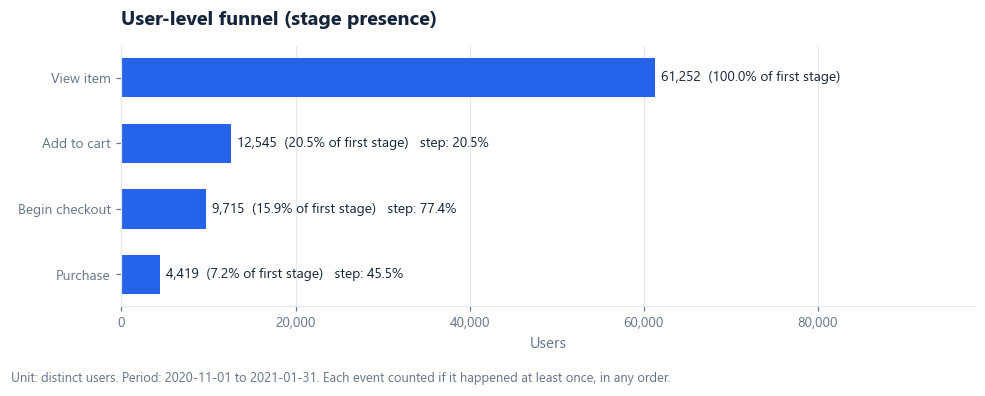

User purchase conversion: 1.64% (4,419 purchasers / 270,154 active users)
Largest step drop-off: View item -> Add to cart: 79.5% of 61,252 users did not continue


In [3]:
funnel = metrics.user_funnel(fact)
display(funnel.style.format({"users": "{:,.0f}", "pct_of_first_stage": "{:.1%}", "step_conversion": "{:.1%}",
                             "drop_off_users": "{:,.0f}", "drop_off_rate": "{:.1%}"}, na_rep="-"))

fig, ax = charts.funnel_chart(funnel, "users", "User-level funnel (stage presence)", "Users")
charts.note(fig, f"Unit: distinct users. Period: {PERIOD}. Each event counted if it happened at least once, in any order.")
charts.save_figure(fig, "03_user_funnel")
plt.show()

k = metrics.headline_kpis(fact)
worst = metrics.largest_drop_off(funnel)
print(f"User purchase conversion: {k['purchase_conversion']:.2%} "
      f"({k['purchasers']:,} purchasers / {k['active_users']:,} active users)")
print(f"Largest step drop-off: {worst['from_stage']} -> {worst['to_stage']}: "
      f"{worst['drop_off_rate']:.1%} of {worst['from_count']:,} users did not continue")

**Interpretation (write this yourself after running on the real export)**

- *Observation:* the step with the largest drop-off rate, with its numerator and denominator.
- *Possible explanation (unproven):* many product views are casual browsing; price, shipping cost or stock could also play a part.
- *Next check:* check whether the same step is the weakest in the sequential session funnel (section 4).

## 2. Reconcile Python with SQL\nThe same funnel was calculated in BigQuery (`sql/04_funnel_analysis.sql` Q20). The two must match exactly.

In [4]:
by_device = metrics.user_funnel_by(fd, "device_category")
cols = ["users", "users_viewed", "users_added_cart", "users_began_checkout", "users_purchased"]
py = by_device.set_index("device_category")[cols].sort_index()
sql = funnel_sql.set_index("device_category")[cols].sort_index()
diff = (py - sql)
display(pd.concat({"python": py, "sql": sql, "difference": diff}, axis=1))
assert (diff.fillna(0) == 0).all().all(), "Python and SQL funnels do not match - investigate before continuing."
print("PASS: Python funnel by device equals the SQL export.")

python                                                     \
                  users users_viewed users_added_cart users_began_checkout   
device_category                                                              
desktop          156905        35697             7268                 5600   
mobile           107175        24160             5007                 3898   
tablet             6074         1395              270                  217   

                                    sql                                \
                users_purchased   users users_viewed users_added_cart   
device_category                                                         
desktop                    2518  156905        35697             7268   
mobile                     1802  107175        24160             5007   
tablet                       99    6074         1395              270   

                                                     difference               \
                users_began_checkout users_purchased      users users_viewed   
device_category                                                                
desktop                         5600            2518          0            0   
mobile                          3898            1802          0            0   
tablet                           217              99          0            0   

                                                                       
                users_added_cart users_began_checkout users_purchased  
device_category                                                        
desktop                        0                    0               0  
mobile                         0                    0               0  
tablet                         0                    0               0

PASS: Python funnel by device equals the SQL export.


## 3. Funnel by device and by channel

,device_category,users,users_viewed,users_added_cart,users_began_checkout,users_purchased,view_to_cart_rate,cart_to_checkout_rate,checkout_to_purchase_rate,view_to_purchase_rate,user_purchase_conversion
0,desktop,"156,905","35,697","7,268","5,600","2,518",20.4%,77.1%,45.0%,7.1%,1.6%
1,mobile,"107,175","24,160","5,007","3,898","1,802",20.7%,77.9%,46.2%,7.5%,1.7%
2,tablet,"6,074","1,395",270,217,99,19.4%,80.4%,45.6%,7.1%,1.6%


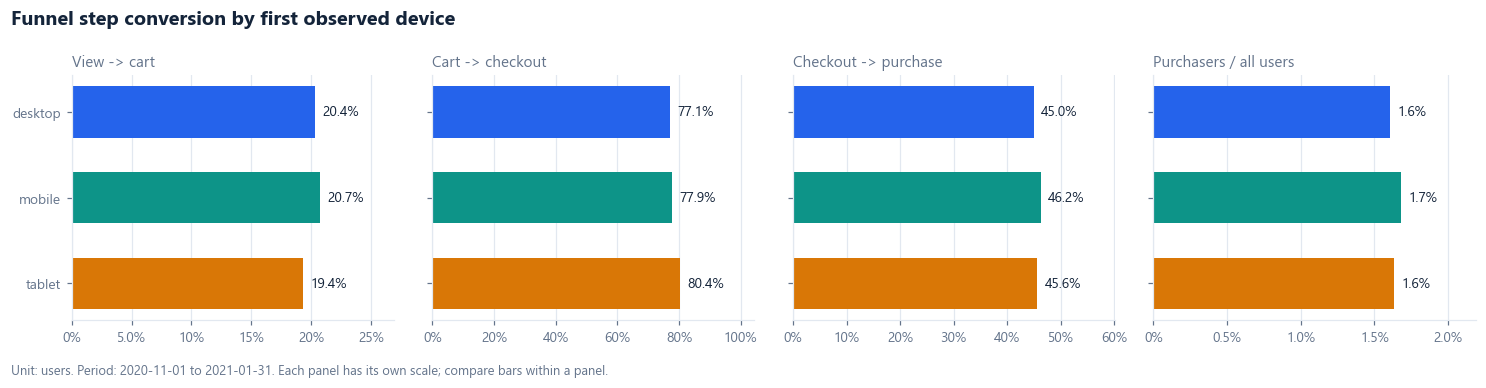

,channel_group,users,users_viewed,users_added_cart,users_began_checkout,users_purchased,view_to_cart_rate,cart_to_checkout_rate,checkout_to_purchase_rate,view_to_purchase_rate,user_purchase_conversion
0,Organic search,"101,742","22,689","4,490","3,490","1,557",19.8%,77.7%,44.6%,6.9%,1.5%
1,Direct,"64,109","14,491","3,096","2,295","1,011",21.4%,74.1%,44.1%,7.0%,1.6%
2,Other,"47,101","10,262","2,121","1,575",680,20.7%,74.3%,43.2%,6.6%,1.4%
3,Referral,"40,019","9,442","1,933","1,574",744,20.5%,81.4%,47.3%,7.9%,1.9%
4,Paid search,"14,282","3,118",597,463,218,19.1%,77.6%,47.1%,7.0%,1.5%
5,Data deleted,"2,901","1,250",308,318,209,24.6%,103.2%,65.7%,16.7%,7.2%


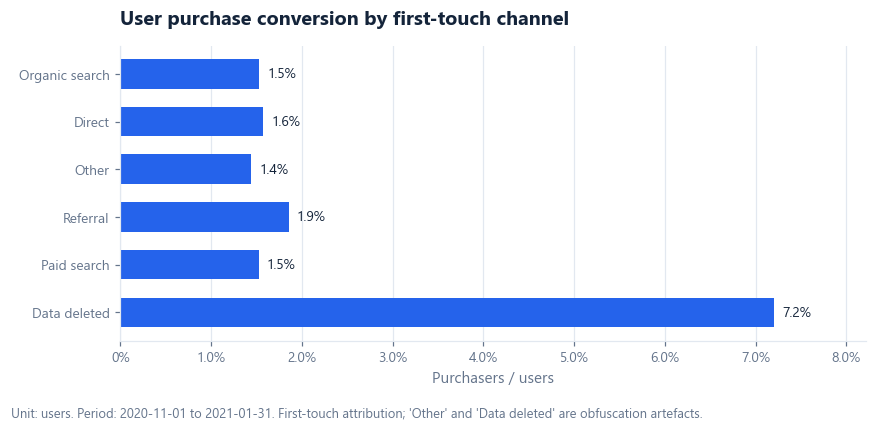

In [5]:
rate_cols = {"view_to_cart_rate": "View -> cart", "cart_to_checkout_rate": "Cart -> checkout",
             "checkout_to_purchase_rate": "Checkout -> purchase", "user_purchase_conversion": "Purchasers / all users"}
fmt = {c: "{:.1%}" for c in rate_cols} | {"view_to_purchase_rate": "{:.1%}"} | {c: "{:,.0f}" for c in cols}

display(by_device.style.format(fmt, na_rep="-"))
fig, axes = charts.grouped_rate_chart(by_device, "device_category", rate_cols, "Funnel step conversion by first observed device")
charts.note(fig, f"Unit: users. Period: {PERIOD}. Each panel has its own scale; compare bars within a panel.")
charts.save_figure(fig, "03_funnel_by_device")
plt.show()

by_channel = metrics.user_funnel_by(fd, "channel_group")
display(by_channel.style.format(fmt, na_rep="-"))
fig, ax = charts.bar_chart(by_channel["channel_group"], by_channel["user_purchase_conversion"],
                           "User purchase conversion by first-touch channel", "Purchasers / users", percent=True)
charts.note(fig, f"Unit: users. Period: {PERIOD}. First-touch attribution; 'Other' and 'Data deleted' are obfuscation artefacts.")
charts.save_figure(fig, "03_conversion_by_channel")
plt.show()

### Is the device difference larger than chance?\nA two-proportion z-test on desktop vs mobile, with 95% Wilson intervals. This says whether the gap is likely to be noise. It does **not** say the device *causes* the gap: desktop and mobile users differ in many ways.

In [6]:
d = by_device.set_index("device_category")
rows = []
for dev in d.index:
    for num, den, label in [("users_added_cart", "users_viewed", "View -> cart"),
                            ("users_began_checkout", "users_added_cart", "Cart -> checkout"),
                            ("users_purchased", "users_began_checkout", "Checkout -> purchase")]:
        lo, hi = metrics.wilson_interval(int(d.loc[dev, num]), int(d.loc[dev, den]))
        rows.append({"device": dev, "step": label, "numerator": int(d.loc[dev, num]),
                     "denominator": int(d.loc[dev, den]),
                     "rate": metrics.safe_div(d.loc[dev, num], d.loc[dev, den]), "ci_low": lo, "ci_high": hi})
ci = pd.DataFrame(rows)
display(ci.style.format({"rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}",
                         "numerator": "{:,.0f}", "denominator": "{:,.0f}"}))

if {"desktop", "mobile"} <= set(d.index):
    for num, den, label in [("users_added_cart", "users_viewed", "View -> cart"),
                            ("users_began_checkout", "users_added_cart", "Cart -> checkout"),
                            ("users_purchased", "users_began_checkout", "Checkout -> purchase")]:
        t = metrics.two_proportion_test(int(d.loc["desktop", num]), int(d.loc["desktop", den]),
                                        int(d.loc["mobile", num]), int(d.loc["mobile", den]))
        print(f"{label:<22} desktop {t['control_rate']:.1%} vs mobile {t['treatment_rate']:.1%} | "
              f"difference {t['absolute_lift']:+.1%} (95% CI {t['ci_low']:+.1%} to {t['ci_high']:+.1%}), p = {t['p_value']:.4f}")
    print("Three tests are run here, so treat p-values near 0.05 as weak evidence (multiple comparisons).")

,device,step,numerator,denominator,rate,ci_low,ci_high
0,desktop,View -> cart,"7,268","35,697",20.4%,19.9%,20.8%
1,desktop,Cart -> checkout,"5,600","7,268",77.1%,76.1%,78.0%
2,desktop,Checkout -> purchase,"2,518","5,600",45.0%,43.7%,46.3%
3,mobile,View -> cart,"5,007","24,160",20.7%,20.2%,21.2%
4,mobile,Cart -> checkout,"3,898","5,007",77.9%,76.7%,79.0%
5,mobile,Checkout -> purchase,"1,802","3,898",46.2%,44.7%,47.8%
6,tablet,View -> cart,270,"1,395",19.4%,17.4%,21.5%
7,tablet,Cart -> checkout,217,270,80.4%,75.2%,84.7%
8,tablet,Checkout -> purchase,99,217,45.6%,39.1%,52.3%


View -> cart           desktop 20.4% vs mobile 20.7% | difference +0.4% (95% CI -0.3% to +1.0%), p = 0.2791
Cart -> checkout       desktop 77.1% vs mobile 77.9% | difference +0.8% (95% CI -0.7% to +2.3%), p = 0.2973
Checkout -> purchase   desktop 45.0% vs mobile 46.2% | difference +1.3% (95% CI -0.8% to +3.3%), p = 0.2234
Three tests are run here, so treat p-values near 0.05 as weak evidence (multiple comparisons).


**Interpretation (write this yourself after running on the real export)**

- *Observation:* which step shows the widest desktop-mobile gap, with both rates, both denominators and the interval.
- *Possible explanation (unproven):* mobile checkout forms may be harder to complete; or mobile visitors may simply have lower intent.
- *Next check:* split the gap by channel and by new vs returning users; then test a change with a real experiment (notebook 05 shows the design).

## 4. Sequential session funnel

,stage,sessions,step_conversion,drop_off_rate
0,View item,"77,020",-,-
1,Add to cart,"15,167",19.7%,80.3%
2,Begin checkout,"5,416",35.7%,64.3%
3,Purchase,"2,834",52.3%,47.7%


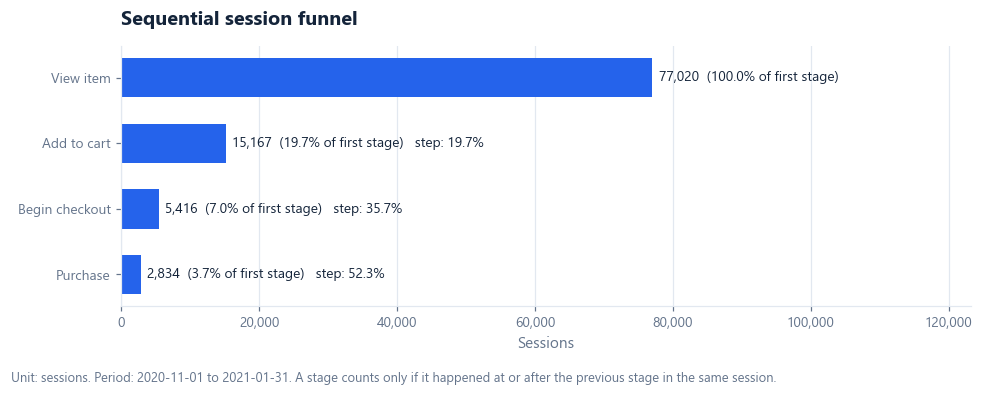

Sessions: 360,129
Sessions with any purchase: 4,848; purchases that followed the full in-session path: 2,834
2,014 purchasing sessions (41.5%) did not follow view -> cart -> checkout inside one session.


,step,user_level_presence,session_sequential,difference
0,View -> cart,20.5%,19.7%,-0.8%
1,Cart -> checkout,77.4%,35.7%,-41.7%
2,Checkout -> purchase,45.5%,52.3%,6.8%


,device_category,sessions,seq_view,seq_cart,seq_checkout,seq_purchase,any_purchase,view_to_cart_rate,cart_to_checkout_rate,checkout_to_purchase_rate,view_to_purchase_rate
0,desktop,"208,942","44,819","8,776","3,109","1,601","2,749",19.6%,35.4%,51.5%,3.6%
1,mobile,"143,185","30,501","6,070","2,194","1,172","1,995",19.9%,36.1%,53.4%,3.8%
2,tablet,"8,002","1,700",321,113,61,104,18.9%,35.2%,54.0%,3.6%


In [7]:
seq = metrics.session_funnel_long(session_funnel)
display(seq.style.format({"sessions": "{:,.0f}", "step_conversion": "{:.1%}", "drop_off_rate": "{:.1%}"}, na_rep="-"))

fig, ax = charts.funnel_chart(seq, "sessions", "Sequential session funnel", "Sessions")
charts.note(fig, f"Unit: sessions. Period: {PERIOD}. A stage counts only if it happened at or after the previous stage in the same session.")
charts.save_figure(fig, "03_session_funnel")
plt.show()

total = metrics.session_funnel_table(session_funnel).iloc[0]
gap = int(total["any_purchase"] - total["seq_purchase"])
print(f"Sessions: {int(total['sessions']):,}")
print(f"Sessions with any purchase: {int(total['any_purchase']):,}; purchases that followed the full "
      f"in-session path: {int(total['seq_purchase']):,}")
print(f"{gap:,} purchasing sessions ({metrics.safe_div(gap, total['any_purchase']):.1%}) did not follow "
      "view -> cart -> checkout inside one session.")

compare = pd.DataFrame({
    "step": ["View -> cart", "Cart -> checkout", "Checkout -> purchase"],
    "user_level_presence": funnel["step_conversion"].iloc[1:].values,
    "session_sequential": seq["step_conversion"].iloc[1:].values})
compare["difference"] = compare["session_sequential"] - compare["user_level_presence"]
display(compare.style.format({c: "{:.1%}" for c in compare.columns[1:]}))

by_dev_seq = metrics.session_funnel_table(session_funnel, by="device_category")
display(by_dev_seq.style.format({c: "{:.1%}" for c in by_dev_seq.columns if c.endswith("_rate")}
                                | {c: "{:,.0f}" for c in ["sessions", "seq_view", "seq_cart", "seq_checkout", "seq_purchase", "any_purchase"]}, na_rep="-"))

**Interpretation (write this yourself after running on the real export)**

- *Observation:* how the session funnel's step rates differ from the user-level ones, and how many purchases skip the in-session path.
- *Possible explanation (unproven):* users often return in a later session to finish a purchase, so a single session understates conversion.
- *Next check:* measure days between a user's first `add_to_cart` and first `purchase` to size cross-session buying.

## What this notebook can and cannot say

- It **can** say how many users or sessions reached each stage, with exact denominators.
- It **cannot** say why users left. Every explanation above is a hypothesis.
- Device = first observed device per user; channel = first-touch source. A user who switches device is still counted once.
- All rates are for the full sample period only.